# Image Data Collection, Processing & Facial Recognition
This notebook implements the first gate of the system: **Start → Facial Recognition → (Access Denied | Product Model)**.

Pipeline: load & display member photos → face detection & cropping → augmentation → feature extraction (`image_features.csv`) → train & evaluate the face model (`face_model.pkl`) → unauthorized-face test.


In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sys, os
sys.path.insert(0, os.path.abspath("../src"))
import image_utils as iu
os.chdir(iu.ROOT)   # run everything from the repo root
records = iu.load_records()
members = sorted({r["member"] for r in records if r["member"] != "unknown"})
print("Members:", members)

Members: ['member_01', 'member_02', 'member_03', 'member_04']


## 1. Image inventory
Naming convention: `images/<member>/<member>_<expression>.jpg`. One image of a non-member is stored in `images/unknown/` for the unauthorized test. It is an illustrated face (source: *add the website here*), not a photo.

In [ ]:
inv = pd.DataFrame([{"member": r["member"], "expression": r["expression"],
                     "file": r["path"], "height": r["image"].shape[0], "width": r["image"].shape[1]}
                    for r in records])
display(pd.crosstab(inv.member, inv.expression))
inv

expression,neutral,other,smile,surprised
member,,,,
member_01,1,0,1,1
member_02,1,0,1,1
member_03,1,0,1,1
member_04,1,0,1,1
unknown,0,1,0,0


,member,expression,file,height,width
0,member_01,neutral,images/member_01/member_01_neutral.jpg,1280,720
1,member_01,smile,images/member_01/member_01_smile.jpg,1280,720
2,member_01,surprised,images/member_01/member_01_surprised.jpg,1280,720
3,member_02,neutral,images/member_02/member_02_neutral.jpg,610,681
4,member_02,smile,images/member_02/member_02_smile.jpg,687,585
5,member_02,surprised,images/member_02/member_02_surprised.jpg,419,463
6,member_03,neutral,images/member_03/member_03_neutral.jpg,578,547
7,member_03,smile,images/member_03/member_03_smile.jpg,595,548
8,member_03,surprised,images/member_03/member_03_surprised.jpg,1182,776
9,member_04,neutral,images/member_04/member_04_neutral.jpg,1280,1260


Every member has exactly one neutral, one smile and one surprised photo. Resolutions differ (phone selfies vs. other cameras), which is handled by cropping and resizing every face to 128×128.

## 2. Sample pictures of each member

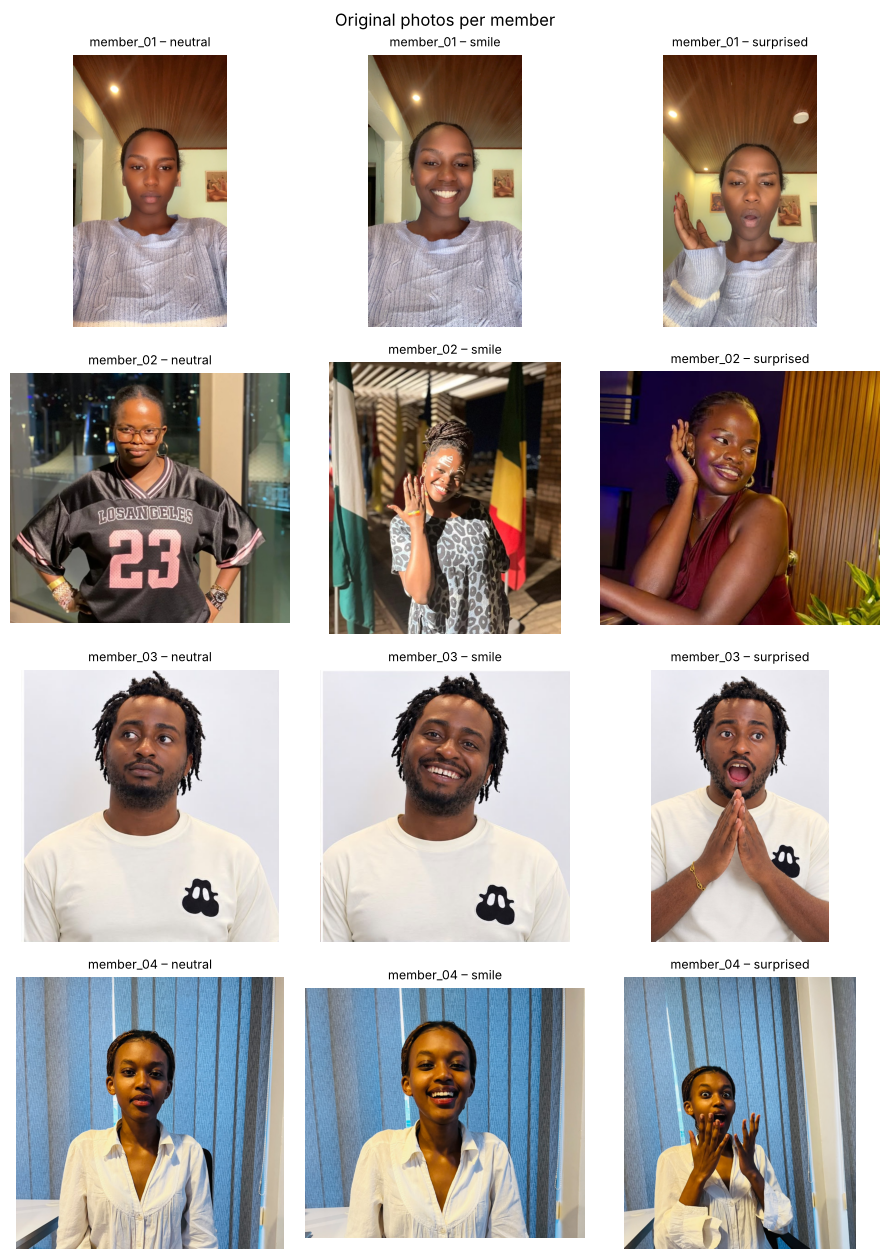

In [ ]:
fig, ax = plt.subplots(len(members), 3, figsize=(9, 3.2 * len(members)))
for i, m in enumerate(members):
    for j, e in enumerate(iu.EXPRESSIONS):
        r = next(r for r in records if r["member"] == m and r["expression"] == e)
        ax[i, j].imshow(r["image"]); ax[i, j].set_title(f"{m} – {e}", fontsize=9); ax[i, j].axis("off")
plt.suptitle("Original photos per member"); plt.tight_layout()
iu.FIGURES.mkdir(exist_ok=True); plt.savefig(iu.FIGURES / "member_samples.png", dpi=110, bbox_inches="tight"); plt.show()

## 3. Face detection & cropping
Faces are found with OpenCV Haar cascades (two detectors, strict then looser settings). Candidate boxes are kept only if their centre is mostly skin-coloured, which rejects false hits on clothing patterns. The box is padded by 15% and resized to 128×128 so background and photo size have less influence.

One photo (`member_02_smile`: face paint, low sunset light) defeated the detector, so its face box was annotated manually in `data/face_boxes.csv`. This is documented rather than hidden.

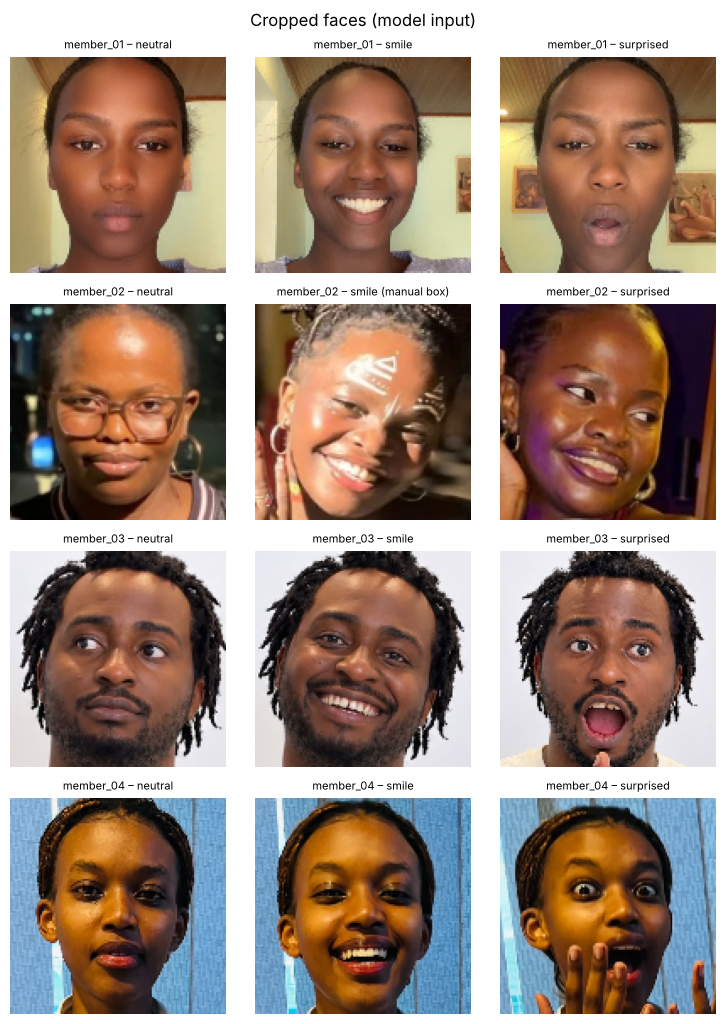

In [ ]:
fig, ax = plt.subplots(len(members), 3, figsize=(7.5, 2.6 * len(members)))
for i, m in enumerate(members):
    for j, e in enumerate(iu.EXPRESSIONS):
        r = next(r for r in records if r["member"] == m and r["expression"] == e)
        ax[i, j].imshow(iu.crop_face(r["image"], r["box"]))
        ax[i, j].set_title(f"{m} – {e}" + (" (manual box)" if r["box"] else ""), fontsize=8); ax[i, j].axis("off")
plt.suptitle("Cropped faces (model input)"); plt.tight_layout()
plt.savefig(iu.FIGURES / "face_crops.png", dpi=110, bbox_inches="tight"); plt.show()

## 4. Augmentation (6 per image)
| Augmentation | Real-world variation it simulates |
|---|---|
| rotate ±15° | head tilt |
| horizontal flip | mirrored selfie camera |
| grayscale | colour/white-balance differences between phones |
| brightness ×1.3 | brighter lighting |
| Gaussian noise | low-light sensor noise |

Each photo produces 7 samples (original + 6), so 12 photos give 84 training samples.

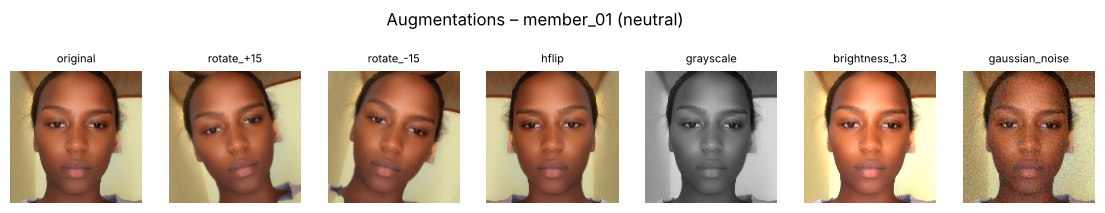

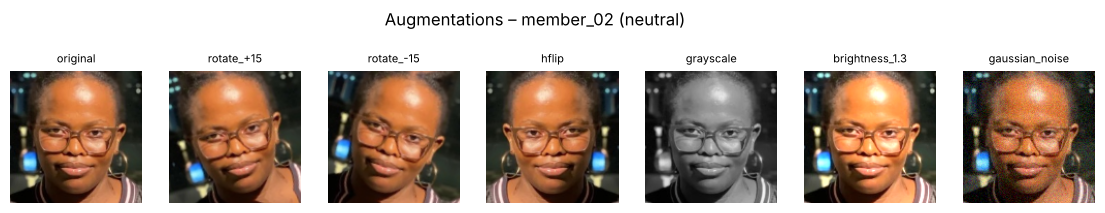

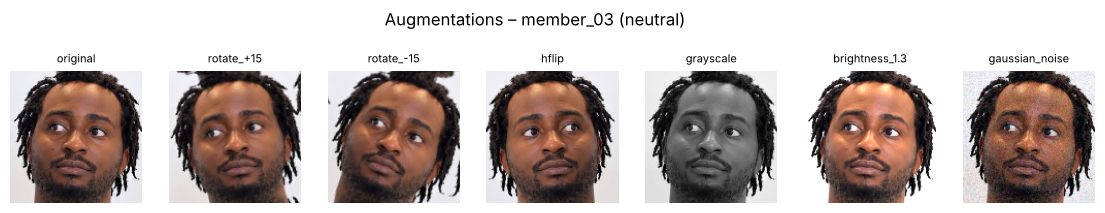

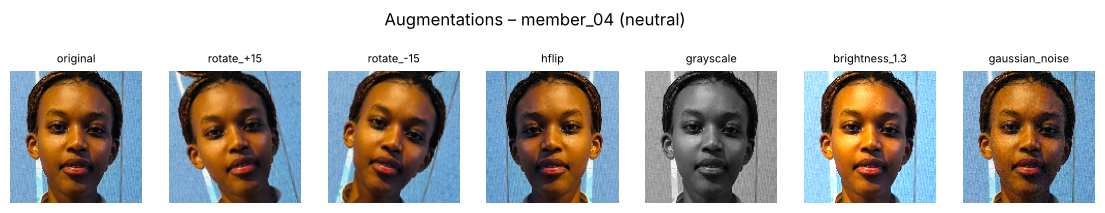

In [ ]:
for m in members:
    r = next(r for r in records if r["member"] == m and r["expression"] == "neutral")
    augs = iu.augment(iu.crop_face(r["image"], r["box"]))
    fig, ax = plt.subplots(1, len(augs), figsize=(14, 2.3))
    for a, (name, im) in zip(ax, augs.items()):
        a.imshow(im); a.set_title(name, fontsize=8); a.axis("off")
    plt.suptitle(f"Augmentations – {m} (neutral)", y=1.05)
    plt.savefig(iu.FIGURES / f"augmentations_{m}.png", dpi=100, bbox_inches="tight"); plt.show()

## 5. Feature extraction → `image_features.csv`
Each face becomes a 382-number vector made of three groups:
- **HSV colour histogram (48):** skin tone and hair colour distribution
- **HOG (324):** edges and shape, i.e. face outline and the geometry of eyes, nose and mouth
- **LBP histogram (10):** fine skin texture, fairly robust to lighting

In [ ]:
feat = iu.build_features(records)
iu.FEATURES_CSV.parent.mkdir(exist_ok=True); feat.to_csv(iu.FEATURES_CSV, index=False)
fcols = [c for c in feat.columns if c not in iu.META_COLS]
print("Shape:", feat.shape, "| features per image:", len(fcols))
print("Missing values:", int(feat[fcols].isna().sum().sum()), "| duplicate rows:", int(feat.duplicated().sum()))
display(feat.groupby(["member", "augmentation"]).size().unstack())
feat.iloc[:5, :10]

Shape: (91, 386) | features per image: 382
Missing values: 0 | duplicate rows: 0


augmentation,brightness_1.3,gaussian_noise,grayscale,hflip,original,rotate_+15,rotate_-15
member,,,,,,,
member_01,3,3,3,3,3,3,3
member_02,3,3,3,3,3,3,3
member_03,3,3,3,3,3,3,3
member_04,3,3,3,3,3,3,3
unknown,1,1,1,1,1,1,1


,member,expression,augmentation,source_image,hist_0,hist_1,hist_2,hist_3,hist_4,hist_5
0,member_01,neutral,original,member_01_neutral.jpg,0.537476,0.240417,0.212646,0.002319,0.0,0.0
1,member_01,neutral,rotate_+15,member_01_neutral.jpg,0.549866,0.233704,0.205322,0.001892,0.0,0.0
2,member_01,neutral,rotate_-15,member_01_neutral.jpg,0.552856,0.225464,0.215576,0.002014,0.0,0.0
3,member_01,neutral,hflip,member_01_neutral.jpg,0.537476,0.240417,0.212646,0.002319,0.0,0.0
4,member_01,neutral,grayscale,member_01_neutral.jpg,1.000000,0.000000,0.000000,0.000000,0.0,0.0


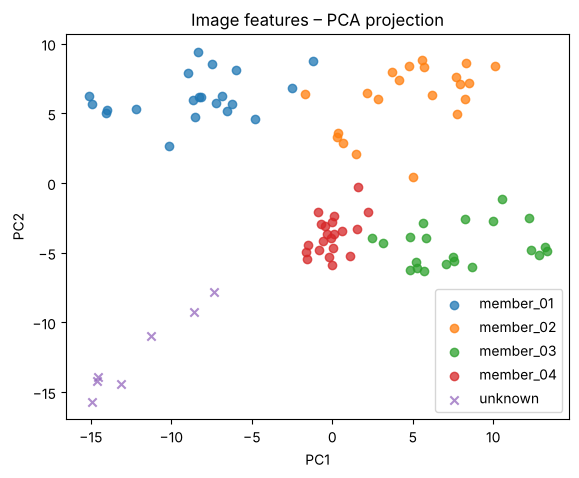

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
Z = PCA(2).fit_transform(StandardScaler().fit_transform(feat[fcols]))
fig, ax = plt.subplots(figsize=(6.5, 5))
for m in sorted(feat.member.unique()):
    k = (feat.member == m).values
    ax.scatter(Z[k, 0], Z[k, 1], label=m, alpha=.75, marker="x" if m == "unknown" else "o")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); ax.set_title("Image features – PCA projection")
plt.savefig(iu.FIGURES / "image_features_pca.png", dpi=110, bbox_inches="tight"); plt.show()

**Interpretation:** each member forms their own cluster, so the features carry identity information. member_02's points are the most spread out because her three photos were taken in three very different settings (lighting, glasses, face paint). The non-member sits away from the member clusters, which the distance check in step 7 relies on.

## 6. Facial recognition model
**Leakage control:** augmented copies of a photo are near-duplicates, so a random split would put copies of the same photo in both train and test and inflate scores. We use **leave-one-expression-out cross-validation**: train on two expressions per member and test on the third. Every test photo is completely unseen.

Models compared: Logistic Regression (scaling → PCA → LR) and Random Forest. Metrics: accuracy, macro F1, log loss.

In [ ]:
res = iu.train()
pd.DataFrame(res["scores"]).T.round(3)

Saved /home/claude/repo/data/image_features.csv: 91 rows x 386 cols
LogisticRegression   accuracy 0.929 | F1 0.910 | log loss 0.152


RandomForest         accuracy 0.952 | F1 0.948 | log loss 0.587

Selected: RandomForest
              precision    recall  f1-score   support

   member_01       1.00      1.00      1.00        21
   member_02       1.00      0.81      0.89        21
   member_03       1.00      1.00      1.00        21
   member_04       0.84      1.00      0.91        21

    accuracy                           0.95        84
   macro avg       0.96      0.95      0.95        84
weighted avg       0.96      0.95      0.95        84



Non-member samples rejected: 100% (n=7)
Saved /home/claude/repo/models/face_model.pkl


,accuracy,f1,log_loss
LogisticRegression,0.929,0.910,0.152
RandomForest,0.952,0.948,0.587


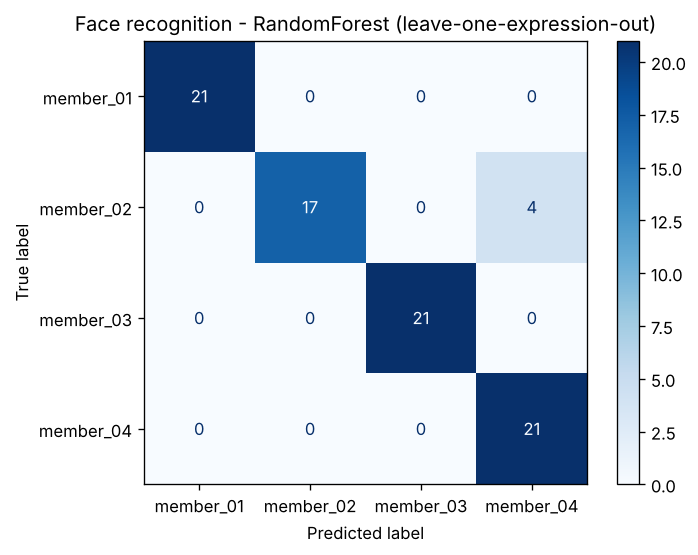

In [ ]:
from IPython.display import Image
Image(str(iu.FIGURES / "face_confusion_matrix.png"))

**Interpretation:** member_01, member_03 and member_04 are recognised perfectly on unseen expressions. The few errors are on member_02, whose photos vary the most, and they are predicted as member_04. Random Forest has the best accuracy and F1. Logistic Regression has lower log loss, meaning its probabilities are better calibrated, but it makes more mistakes. We select on F1 because a wrong identity is the costly error for an authentication system.

**Caution:** each member's photos share a background and lighting, so some of the accuracy may come from those cues rather than the face itself. Cropping reduces this but doesn't remove it. Photos taken in new places would give a stricter test.

## 7. Unauthorized attempt
A classifier always picks *some* member, so a face is accepted only if both:
1. its **confidence** is at or above the 10th percentile of correct cross-validation predictions, and
2. its **distance** to the nearest enrolled face is within the 95th percentile (+10%) of genuine distances.

In [ ]:
print(f"Confidence threshold: {res['threshold']:.2f} | distance threshold: {res['dist_threshold']:.2f}\n")
tests = [f"images/{m}/{m}_neutral.jpg" for m in members] + ["images/unknown/non_member_1.jpg"]
rows = []
for p in tests:
    member, conf = iu.predict_face(p)
    rows.append({"input": p, "prediction": member or "—", "confidence": round(conf, 2),
                 "decision": "GRANTED" if member else "ACCESS DENIED"})
pd.DataFrame(rows)

Confidence threshold: 0.50 | distance threshold: 1.46



,input,prediction,confidence,decision
0,images/member_01/member_01_neutral.jpg,member_01,1.00,GRANTED
1,images/member_02/member_02_neutral.jpg,member_02,0.98,GRANTED
2,images/member_03/member_03_neutral.jpg,member_03,0.98,GRANTED
3,images/member_04/member_04_neutral.jpg,member_04,1.00,GRANTED
4,images/unknown/non_member_1.jpg,—,0.35,ACCESS DENIED


**Interpretation:** all four members' neutral photos are accepted with high confidence, and the non-member is denied (below the confidence threshold).

**Limitation:** the non-member is an illustration, so part of why it is rejected may be that it doesn't look like a photo (flat colours, no skin texture) rather than that it is a different person. A photo of a real non-member, taken the same way as the members' photos, would be a stricter test.

## 8. Use in the command-line app
```python
from image_utils import predict_face
member, conf = predict_face("path/to/face.jpg")   # None -> Access Denied
```